In [1]:
import pandas as pd
import yfinance as yf
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm



[*********************100%***********************]  5 of 5 completed


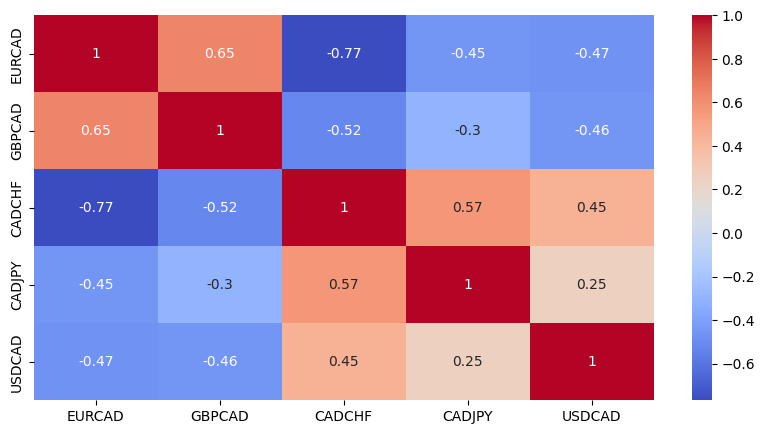

In [6]:
tickers = ["EURCAD=X", "GBPCAD=X", "CADCHF=X", "CADJPY=X", "USDCAD=X"]

df_prices = yf.download(tickers, period="10y")[["Close"]]
df_prices.columns = ["EURCAD", "GBPCAD", "CADCHF", "CADJPY", "USDCAD"]

df_returns = df_prices.pct_change(fill_method=None).dropna()

plt.figure(figsize=(10,5))
sns.heatmap(df_returns.corr(), annot=True, cmap="coolwarm")
plt.show()


In [9]:
X = df_returns[["GBPCAD", "CADCHF", "USDCAD"]]
Y = df_returns["EURCAD"]

X = sm.add_constant(X)
regression = sm.OLS(Y,X).fit()

print(regression.summary())



                            OLS Regression Results                            
Dep. Variable:                 EURCAD   R-squared:                       0.677
Model:                            OLS   Adj. R-squared:                  0.676
Method:                 Least Squares   F-statistic:                     1808.
Date:                Wed, 11 Mar 2026   Prob (F-statistic):               0.00
Time:                        16:25:07   Log-Likelihood:                 11633.
No. Observations:                2598   AIC:                        -2.326e+04
Df Residuals:                    2594   BIC:                        -2.323e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0001    5.4e-05     -1.862      0.0